## Tecno Customer Churn Prediction
### Supervised Learning- Classification 


This project is an Machine Learning application developed to predict customer churn for a telecom company, classified into 2 classes :

 No →   Customer stayed
 
 Yes →  Customer churned

About the dataset :
The project uses the Telco Customer Churn dataset containing approximately 7,000 customer records, dowloaded from kaggle : 
     https://www.kaggle.com/datasets/blastchar/telco-customer-churn
     





####  1. Install libraries

In [1]:
import pandas as pd

#### 2. Explore the Data

In [2]:
#load the dataset
df = pd.read_csv("../hands-on-project/WA_Fn-UseC_-Telco-Customer-Churn.csv")
tecno_custmr = df.copy()
tecno_custmr.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
tecno_custmr.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [4]:
tecno_custmr.shape

(7043, 21)

In [4]:
tecno_custmr.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
tecno_custmr.isna().sum() # no null values 

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [6]:
tecno_custmr.duplicated().sum() #no duplicated rows

np.int64(0)

In [7]:
tecno_custmr["TotalCharges"].dtypes

<StringDtype(storage='python', na_value=nan)>

In [8]:
#convert  TotalCharges values into numeric 
tecno_custmr["TotalCharges"] = pd.to_numeric(
    tecno_custmr["TotalCharges"],
    errors="coerce"
)
tecno_custmr["TotalCharges"].dtypes

dtype('float64')

In [9]:
tecno_custmr.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

In [10]:
tecno_custmr.isna().sum()  #after converting into numeric values, missing values appear 

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [11]:
tecno_custmr['TotalCharges'].isna().sum()

np.int64(11)

In [13]:
#totalcharges = tenure * monthlycharges 
tecno_custmr['TotalCharges'] = tecno_custmr['TotalCharges'].fillna(tecno_custmr['tenure']* tecno_custmr['MonthlyCharges'])
tecno_custmr['TotalCharges'].isna().sum()

np.int64(0)

#### 3. Prepare the Data

In [14]:
# class balance: how many yes vs no?
tecno_custmr['Churn'].value_counts()
#no balance classes, we should change the weight 
# No →  73.46% Customer stayed
# Yes → 26.54% Customer churned

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [15]:
print(tecno_custmr["Churn"].value_counts(normalize=True) * 100)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


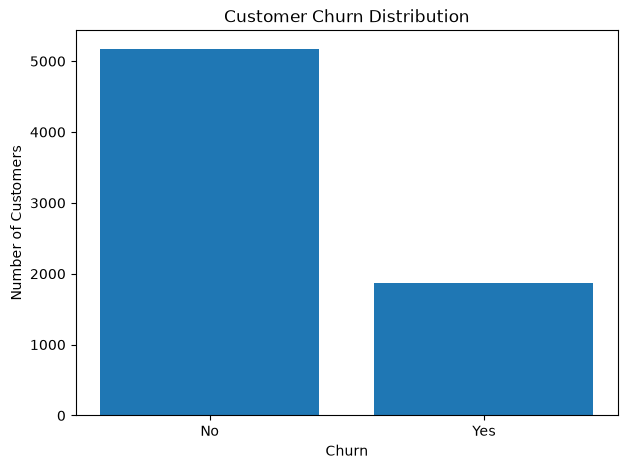

In [16]:
import matplotlib 
import matplotlib.pyplot as plt 

churn_counts = tecno_custmr['Churn'].value_counts()
plt.figure(figsize=(7, 5))
plt.bar(churn_counts.index, churn_counts.values)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

In [17]:
#Encode target classes : yes -> 1, no -> 0
tecno_custmr["Churn"] = tecno_custmr["Churn"].map({
    "No": 0,
    "Yes": 1
})

print(df["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [18]:
tecno_custmr.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [19]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

#Define X & y, remove custumerid culumn, index column
X = tecno_custmr.drop(['customerID', 'Churn'], axis =1,  errors='ignore')
y = tecno_custmr['Churn']
X.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


#### 4. Train/Test Split

In [20]:
#split the dataset 
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((5282, 19), (1761, 19), (5282,), (1761,))

#### 5. Preprocessing Pipeline 

In [21]:
# from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

#define X and y
#split the data

# Identify categorical and numerical features
categorical_features = X_train.select_dtypes(
    include=['object', 'string', 'category', 'bool']
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=['number']
).columns.tolist()

# Preprocessing
preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
    ('num', StandardScaler(), numerical_features)
])


#logistic regression 
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced"
            )
        )
    ]
)

logistic_model.fit(
    X_train,
    y_train
)



,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

#### 6. Train Models 

In [22]:
#random forest classifier 
from sklearn.ensemble import RandomForestClassifier
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=10,
                random_state=42,
                class_weight="balanced"
            )
        )
    ]
)

rf_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

#### 7. Predictions 

In [23]:

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model
}

results = []

for name, model in models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred), #~55%
        "Recall":  recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })
    

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
)

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.731403,0.497409,0.818763,0.618856,0.837841
1,Random Forest,0.754117,0.526549,0.761194,0.622493,0.832276


In [24]:
logistic_model.predict(X_test[:5])

array([0, 1, 0, 1, 0])

In [25]:
logistic_model.predict_proba(X_test[:5])

array([[0.77913184, 0.22086816],
       [0.49765003, 0.50234997],
       [0.99047741, 0.00952259],
       [0.47972795, 0.52027205],
       [0.55423606, 0.44576394]])

In [26]:
rf_model.predict(X_test[:5])

array([0, 0, 0, 1, 1])

In [27]:
rf_model.predict_proba(X_test[:5])

array([[0.50922428, 0.49077572],
       [0.68224672, 0.31775328],
       [0.99726956, 0.00273044],
       [0.45672242, 0.54327758],
       [0.49468332, 0.50531668]])

In [37]:
print(f"LogReg accuracy: {logistic_model.score(X_test, y_test):.3f}")
print(f"Forest accuracy: {rf_model.score(X_test, y_test):.3f}")

LogReg accuracy: 0.731
Forest accuracy: 0.754


#### 8. Evaluation

In [28]:
#evaluation

from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay

y_pred = rf_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))



Accuracy: 0.7541169789892107

Confusion Matrix:
 [[971 321]
 [112 357]]

Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.75      0.82      1292
           1       0.53      0.76      0.62       469

    accuracy                           0.75      1761
   macro avg       0.71      0.76      0.72      1761
weighted avg       0.80      0.75      0.77      1761



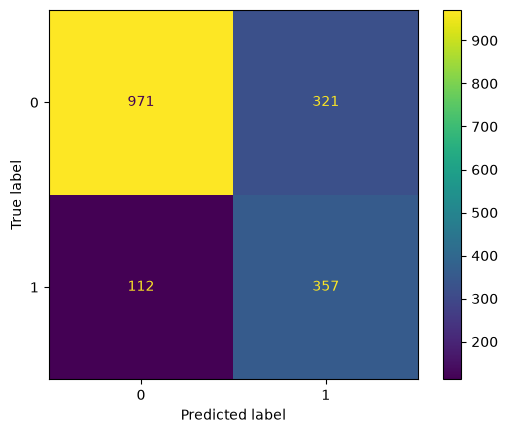

In [29]:
ConfusionMatrixDisplay.from_predictions(y_true=y_test, y_pred= y_pred);

AUC: 0.832


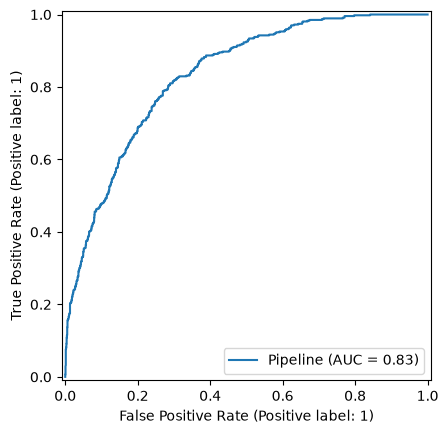

In [30]:
from sklearn.metrics import RocCurveDisplay, roc_auc_score

# Probabilities of the positive class
y_probs = rf_model.predict_proba(X_test)[:, 1]

print(f"AUC: {roc_auc_score(y_test, y_probs):.3f}")


RocCurveDisplay.from_estimator(estimator= rf_model, X=X_test, y=y_test);


#### 9. Choose best parameters 
#####  Its seems that random forest classifier is better than logistic regression(according to the accuracy, precision and confidence prob) 

In [32]:
from sklearn.model_selection import GridSearchCV

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                random_state=42,
                class_weight="balanced"
            )
        )
    ]
)
param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [5, 10, 15],
    "classifier__min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(
    X_train,
    y_train
)

print("\n Best Parameters:")
print(grid_search.best_params_)

print("\n Best Cross-Validation ROC-AUC:")
print(round(grid_search.best_score_, 4))


Fitting 5 folds for each of 12 candidates, totalling 60 fits

 Best Parameters:
{'classifier__max_depth': 5, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}

 Best Cross-Validation ROC-AUC:
0.847


#### 10. Evaluate the best model

In [33]:
best_rf = grid_search.best_estimator_

print("Best parameters:", grid_search.best_params_)
print("Best CV F1:", grid_search.best_score_)

y_pred = best_rf.predict(X_test)
ybest_proba = best_rf.predict_proba(X_test)[:, 1]
ybest_proba

Best parameters: {'classifier__max_depth': 5, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}
Best CV F1: 0.8469522123770098


array([0.45354141, 0.48681464, 0.03541991, ..., 0.36569969, 0.40776679,
       0.68211094], shape=(1761,))

In [38]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.730266893810335

Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.70      0.79      1292
           1       0.50      0.81      0.62       469

    accuracy                           0.73      1761
   macro avg       0.70      0.76      0.70      1761
weighted avg       0.80      0.73      0.75      1761



[[905 387]
 [ 88 381]]


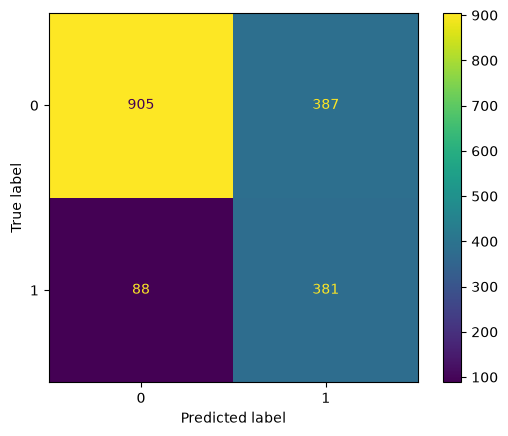

In [39]:
print(confusion_matrix(y_test, y_pred))
ConfusionMatrixDisplay.from_predictions(y_true=y_test, y_pred= y_pred);

#### 11. Save  The Best Model

In [41]:
import pickle
from joblib import dump, load


# pickle
pickle.dump(best_rf, open("tecno_churn_customer_model.pkl", "wb"))
loaded = pickle.load(open("tecno_churn_customer_model.pkl", "rb"))
print(f"Loaded (pickle) accuracy: {loaded.score(X_test, y_test):.3f}")

# joblib
dump(best_rf, "tecno_churn_customer_model.joblib")
loaded_joblib = load("tecno_churn_customer_model.joblib")
print(f"Loaded (joblib) accuracy: {loaded_joblib.score(X_test, y_test):.3f}")




Loaded (pickle) accuracy: 0.730
Loaded (joblib) accuracy: 0.730
